# Advective contribution to atmospheric energy budget
The atmospheric energy budget has a term related to advection, which I have previously obtained as a residual. Here, I compare this to a direct approach to calculating the advection component. The direct component has the advantage that the advection can be split up between zonal, meridional, and vertical advection.

In [12]:
import sys
import os
import inspect
from matplotlib.lines import Line2D


from isca_tools.thesis.adiabat_theory import get_temp_adiabat
from isca_tools.thesis.season_annual_harmonic import get_phase_amp
from isca_tools.thesis.surface_flux_taylor_2layer import get_sensitivity_lh
from isca_tools.utils.moist_physics import sphum_sat
from isca_tools.utils.numerical import sum_complex
from isca_tools.thesis.lapse_integral_simple import get_lnb_ind, get_temp_2_layer_approx
from isca_tools.utils.xarray import wrap_with_apply_ufunc, isel_float
from isca_tools.utils.numerical import spline_deriv_nonperiodic
from isca_tools.utils.land import get_land_coords, get_ocean_coords
from isca_tools.utils import area_weighting

# REMOTE - So can access functions in isca_tools which is in home/Isca directory
# sys.path.append(os.path.join(os.environ['HOME'], 'Isca'))
# LOCAL - So can access functions in isca_tools which is in StAndrews/Isca
sys.path.append(os.environ['PWD'])
from isca_tools.utils.constants import kappa, L_v, c_p, c_p_ocean, rho_ocean, Stefan_Boltzmann, R, R_v, g, radius_earth, lapse_dry
from tqdm.notebook import tqdm
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from isca_tools.plot import fig_resize, update_fontsize, update_linewidth, savefig, label_subplots
import isca_tools
from isca_tools.utils.load import load_namelist
from isca_tools.utils.base import mass_weighted_vertical_integral
# Use custom matplotlib style for publishing
plt.style.use('/Users/joshduffield/Documents/StAndrews/Isca/jobs/tau_sweep/aquaplanet/publish_figures/publish.mplstyle')
ax_linewidth = plt.rcParams['axes.linewidth']

In [21]:
from jobs.thesis_season.publish_figs.load import smooth_n_days, get_annual_zonal_mean, spline_deriv_periodic_xr, frierson_atmospheric_heating, day_seconds, width
# var_keep = ['ps', 't_surf', 'temp', 'height', 'sphum', 'ucomp', 'vcomp', 'omega', 'swdn_toa', 'swdn_sfc', 'lwup_sfc', 'lwdn_sfc', 'olr', 'flux_t', 'flux_lhe']

exp_dir = 'nerc_srm/simulations/column/'
exp_name = ['base', 'play/k=1_5_sw_reduced', 'play/k=1_5']
n_exp = len(exp_name)
# namelist = load_namelist(exp_path)
ds = []
for i in tqdm(range(n_exp)):
    exp_path = os.path.join(exp_dir, exp_name[i])
    namelist = load_namelist(exp_path)
    print(namelist['constants_nml'])
    ds.append(isca_tools.load_dataset(exp_path, first_month_file=2).load())

  0%|          | 0/3 [00:00<?, ?it/s]

Namelist({'omega': 7.292115e-05, 'pstd': 1000000.0, 'pstd_mks': 100000.0})
Namelist({'omega': 7.292115e-05, 'pstd': 1000000.0, 'pstd_mks': 100000.0, 'solar_const': 1340.86})
Namelist({'omega': 7.292115e-05, 'pstd': 1000000.0, 'pstd_mks': 100000.0})


In [20]:
for i in range(n_exp):
    print(f"Experiment {i}: {area_weighting(ds[i].t_surf).mean():.2f}")

Experiment 0: 285.17
Experiment 1: 290.25
Experiment 2: 290.25


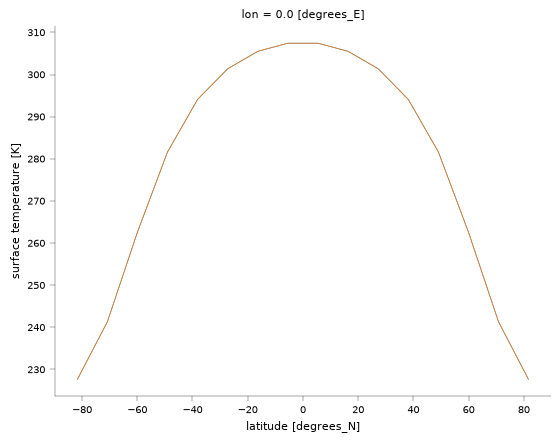

In [25]:
ds[1].t_surf.mean(dim='time').plot()
ds[2].t_surf.mean(dim='time').plot()

In [29]:
ds_use = isca_tools.load_dataset('nerc_srm/simulations/column/base').load()

/Users/joshduffield/Documents/StAndrews/Isca/isca_tools/utils/load.py:68: UserWarning: First month saved is 2 not 1.
  warnings.warn(f'First month saved is {first_month} not 1.')
